# Test du modèle sur des audios de OcOr (Corpus of Occitan Oral Narratives)
## 1. Imports

In [1]:
import torchaudio
import torch
from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC
import panphon
import panphon.distance

import csv
import os
import requests
import json
import re
from jiwer import wer

from datasets import Dataset, Audio
from nltk.metrics.distance import edit_distance, edit_distance_align
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from pathlib import Path

from tqdm import tqdm

/home/manon/Documents/Master/M2/stage/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from models.w2v2p import load_model, predict, predict_from_dataset, predict_simple
from data.get_data import get_sentences_from_tsv, get_phonemes_from_LC, get_phonemes_from_json, get_x, get_ref
from data.form_dataset import make_dataset
from data.make_groups import regroupement, regroupement_mixte, split_variantes
from data.get_closest import closest
from data.cleaning import clean_text, clean_list
from evaluation.metrics import get_per_nltk, per_by_variant, per_aligne_nltk, per_aligne_by_var, get_pfer_panphon, pfer_var
from evaluation.pipeline import evaluate_dataset
from evaluation.alignment import alignement_ajuste
from evaluation.plotting import matrice_confusion

## 2. Load paths

In [3]:
base_path = Path("/home/manon/Documents/Master/M2/stage")
ocor_path = base_path / "data/OOT"

## 3. Load model

In [4]:
processor, model = load_model("facebook/wav2vec2-xlsr-53-espeak-cv-ft")

Loading weights: 100%|██████████| 424/424 [00:00<00:00, 1072.56it/s, Materializing param=wav2vec2.masked_spec_embed]                                            


## 4. Load data

In [5]:
sentences = []
for part in ["part1", "part2", "part3"]:
    sent_path = ocor_path / f"taupa_grapaud/taupa_grapaud_{part}.txt"
    with open(sent_path, 'r', encoding='utf-8') as file:
        sentences.append(file.read())

In [6]:
y_test = get_phonemes_from_json(base_path/"scripts_propres/phonemes_taupa.json")

In [7]:
y_test_gascon = [tlist[1] for tlist in y_test]

In [8]:
X_test = []
audio_path = ocor_path/"taupa_grapaud"
for part in ["part1", "part2", "part3"]:
    X_test.append(os.path.join(audio_path, f"taupa_grapaud_{part}.mp3"))

## 5. Build dataset
Not necessary here

## 6. Run inference


In [9]:
y_pred = []
for audio in X_test:
    prediction = predict_simple(model, processor, audio)
    y_pred.extend(prediction)

y_pred

['e b e ɔ aʊ t ə s k ɔ p s l uː k a p aʊ t a w e y n ə k u ə a p aɪ p a d y l s a p eɪ l a t aʊ p ɐ aʊ e ɡ u z y n s a p aɪ p a d i k u e l a t aɪ p ɐ e s t u r u n d e b a l a t ɛ r e r a',
 'a p e l o l u k a p aʊ t e s t u ʒ u n ts e l a t ɛ r a d a n l a z ɛ r v ə s a p e n i b e ð e r e e t a l ɔ h ə a ŋ aɪ t y m ʃ o ɾ y y p a k t a n s i ɲ a t y n p a k t t u d y s b a n s a n j a t y m e v aɪ j r a s t u z y l s a p eɪ ʒ o m d e v a r e m a k u ə a l o ʁ a k o z a t a k i e l u k a p a b a j a t s u z s a k u a l a t aʊ p ə e l a t aʊ k a v a j a s u z y l s aʊ r a p aʊ t',
 'a k o s p ɾ a k o k e k a n k aʊ k y s a ɲ i k aʊ k a r e k a k o s p a t ɾ o v j e ŋ d i n t e h a j k o m a l a t a m p o p e o k a b aʊ']

In [10]:
y_test_clean, y_pred_clean = clean_list(y_test_gascon), clean_list(y_pred)
print(y_test_clean)
print(y_pred_clean)

['hebeɔawteskɔtslukrapawtabɛynɔkuɔapɛjpasdyʎsapɛjlatawpɔabɛduzyʎsapɛjpasdekuɔelatawpɔestutʒurdabanlatɛrrɔelɔ', 'apɛjlukrapawtetestutʒursyslatɛrrɔdenlazɛrbɔzapɛjnibedɛreehalarɔanhɛjtytʃɔzɔypakteasinnatypaktetutsdysbamsaɲatymebaʎarastuzyʎsapɛjʒutebaʎimakuɔalarɔakɔsatawkelukrapawtabaʎatsussakuɔalatawpɔelatawpɔabaʎatsuzyʎsawkrapawt', 'akɔsprakɔkekankawkysaɲɔkawkarreakɔspastrɔpbjeliditstɛahkumɔlatawpɔperlukrapawt']
['ebeɔaʊtəskɔpsluːkapaʊtaweynəkuəapaɪpadylsapeɪlataʊpɐaʊeɡuzynsapaɪpadikuelataɪpɐesturundebalatɛrera', 'apelolukapaʊtestuʒuntselatɛradanlazɛrvəsapenibeðereetalɔhəaŋaɪtymʃoɾyypaktansiɲatynpakttudysbansanjatymevaɪjrastuzylsapeɪʒomdevaremakuəaloʁakozatakielukapabajatsuzsakualataʊpəelataʊkavajasuzylsaʊrapaʊt', 'akospɾakokekankaʊkysaɲikaʊkarekakospatɾovjeŋdintehajkomalatampopeokabaʊ']


## 7. Evaluate

In [11]:
per = get_per_nltk(y_test_clean, y_pred_clean, "test")
print("PER : ", per)

PER :  38.84%


## 8. Align and Re-evaluate

In [12]:
y_test_aligned, y_pred_aligned = [], []

for i in range(len(y_test_clean)):
    test, pred = alignement_ajuste(y_test_clean[i], y_pred_clean[i])
    y_test_aligned.extend(test)
    y_pred_aligned.extend(pred)


100%|██████████| 78/78 [00:00<00:00, 1496.05it/s]


In [13]:
print(y_test_aligned)
print(y_pred_aligned)

['h', 'e', 'b', 'e', 'ɔ', 'a', 'w', 't', 'e', 's', 'k', 'ɔ', 't', 's', 'l', 'u', '-', 'k', 'r', 'a', 'p', 'a', 'w', 't', 'a', 'b', 'ɛ', 'y', 'n', 'ɔ', 'k', 'u', 'ɔ', 'a', 'p', 'ɛ', 'j', 'p', 'a', 's', 'd', 'y', 'ʎ', 's', 'a', 'p', 'ɛ', 'j', 'l', 'a', 't', 'a', 'w', 'p', 'ɔ', 'a', '-', 'b', 'ɛ', 'd', 'u', 'z', 'y', 'ʎ', 's', 'a', 'p', 'ɛ', 'j', 'p', 'a', 's', 'd', 'e', 'k', 'u', 'ɔ', 'e', 'l', 'a', 't', 'a', 'w', 'p', 'ɔ', 'e', 's', 't', 'u', 't', 'ʒ', 'u', 'r', 'd', 'a', 'b', 'a', 'n', 'l', 'a', 't', 'ɛ', 'r', 'r', 'ɔ', 'e', 'l', 'ɔ', 'a', 'p', 'ɛ', '-', 'j', 'l', 'u', 'k', 'r', 'a', 'p', 'a', 'w', 't', 'e', 't', 'e', 's', 't', 'u', 't', 'ʒ', 'u', 'r', 's', 'y', 's', '-', 'l', 'a', 't', 'ɛ', 'r', 'r', 'ɔ', 'd', 'e', 'n', 'l', 'a', 'z', 'ɛ', 'r', 'b', 'ɔ', 'z', 'a', 'p', 'ɛ', 'j', 'n', 'i', 'b', 'e', 'd', 'ɛ', 'r', 'e', 'e', 'h', 'a', 'l', 'a', 'r', 'ɔ', 'a', 'n', 'h', 'ɛ', 'j', 't', 'y', 't', 'ʃ', 'ɔ', 'z', 'ɔ', 'y', 'p', 'a', 'k', 't', 'e', 'a', '-', 's', 'i', 'n', 'n', 'a', 't', 'y',

In [14]:
aligned_per = get_per_nltk(y_test_aligned, y_pred_aligned, "test")
print("Aligned PER : ", aligned_per)

Aligned PER :  37.86%


## 9. Confusion matrix

Len labels : 38 | Len y_variant_phonemes : 412 | Len y_next_variant : 412
y_true: ['h', 'e', 'b', 'e', 'ɔ', 'a', 'w', 't', 'e', 's', 'k', 'ɔ', 't', 's', 'l', 'u', '-', 'k', 'r', 'a', 'p', 'a', 'w', 't', 'a', 'b', 'ɛ', 'y', 'n', 'ɔ', 'k', 'u', 'ɔ', 'a', 'p', 'ɛ', 'j', 'p', 'a', 's', 'd', 'y', 'ʎ', 's', 'a', 'p', 'ɛ', 'j', 'l', 'a', 't', 'a', 'w', 'p', 'ɔ', 'a', '-', 'b', 'ɛ', 'd', 'u', 'z', 'y', 'ʎ', 's', 'a', 'p', 'ɛ', 'j', 'p', 'a', 's', 'd', 'e', 'k', 'u', 'ɔ', 'e', 'l', 'a', 't', 'a', 'w', 'p', 'ɔ', 'e', 's', 't', 'u', 't', 'ʒ', 'u', 'r', 'd', 'a', 'b', 'a', 'n', 'l', 'a', 't', 'ɛ', 'r', 'r', 'ɔ', 'e', 'l', 'ɔ', 'a', 'p', 'ɛ', '-', 'j', 'l', 'u', 'k', 'r', 'a', 'p', 'a', 'w', 't', 'e', 't', 'e', 's', 't', 'u', 't', 'ʒ', 'u', 'r', 's', 'y', 's', '-', 'l', 'a', 't', 'ɛ', 'r', 'r', 'ɔ', 'd', 'e', 'n', 'l', 'a', 'z', 'ɛ', 'r', 'b', 'ɔ', 'z', 'a', 'p', 'ɛ', 'j', 'n', 'i', 'b', 'e', 'd', 'ɛ', 'r', 'e', 'e', 'h', 'a', 'l', 'a', 'r', 'ɔ', 'a', 'n', 'h', 'ɛ', 'j', 't', 'y', 't', 'ʃ', 'ɔ', 'z

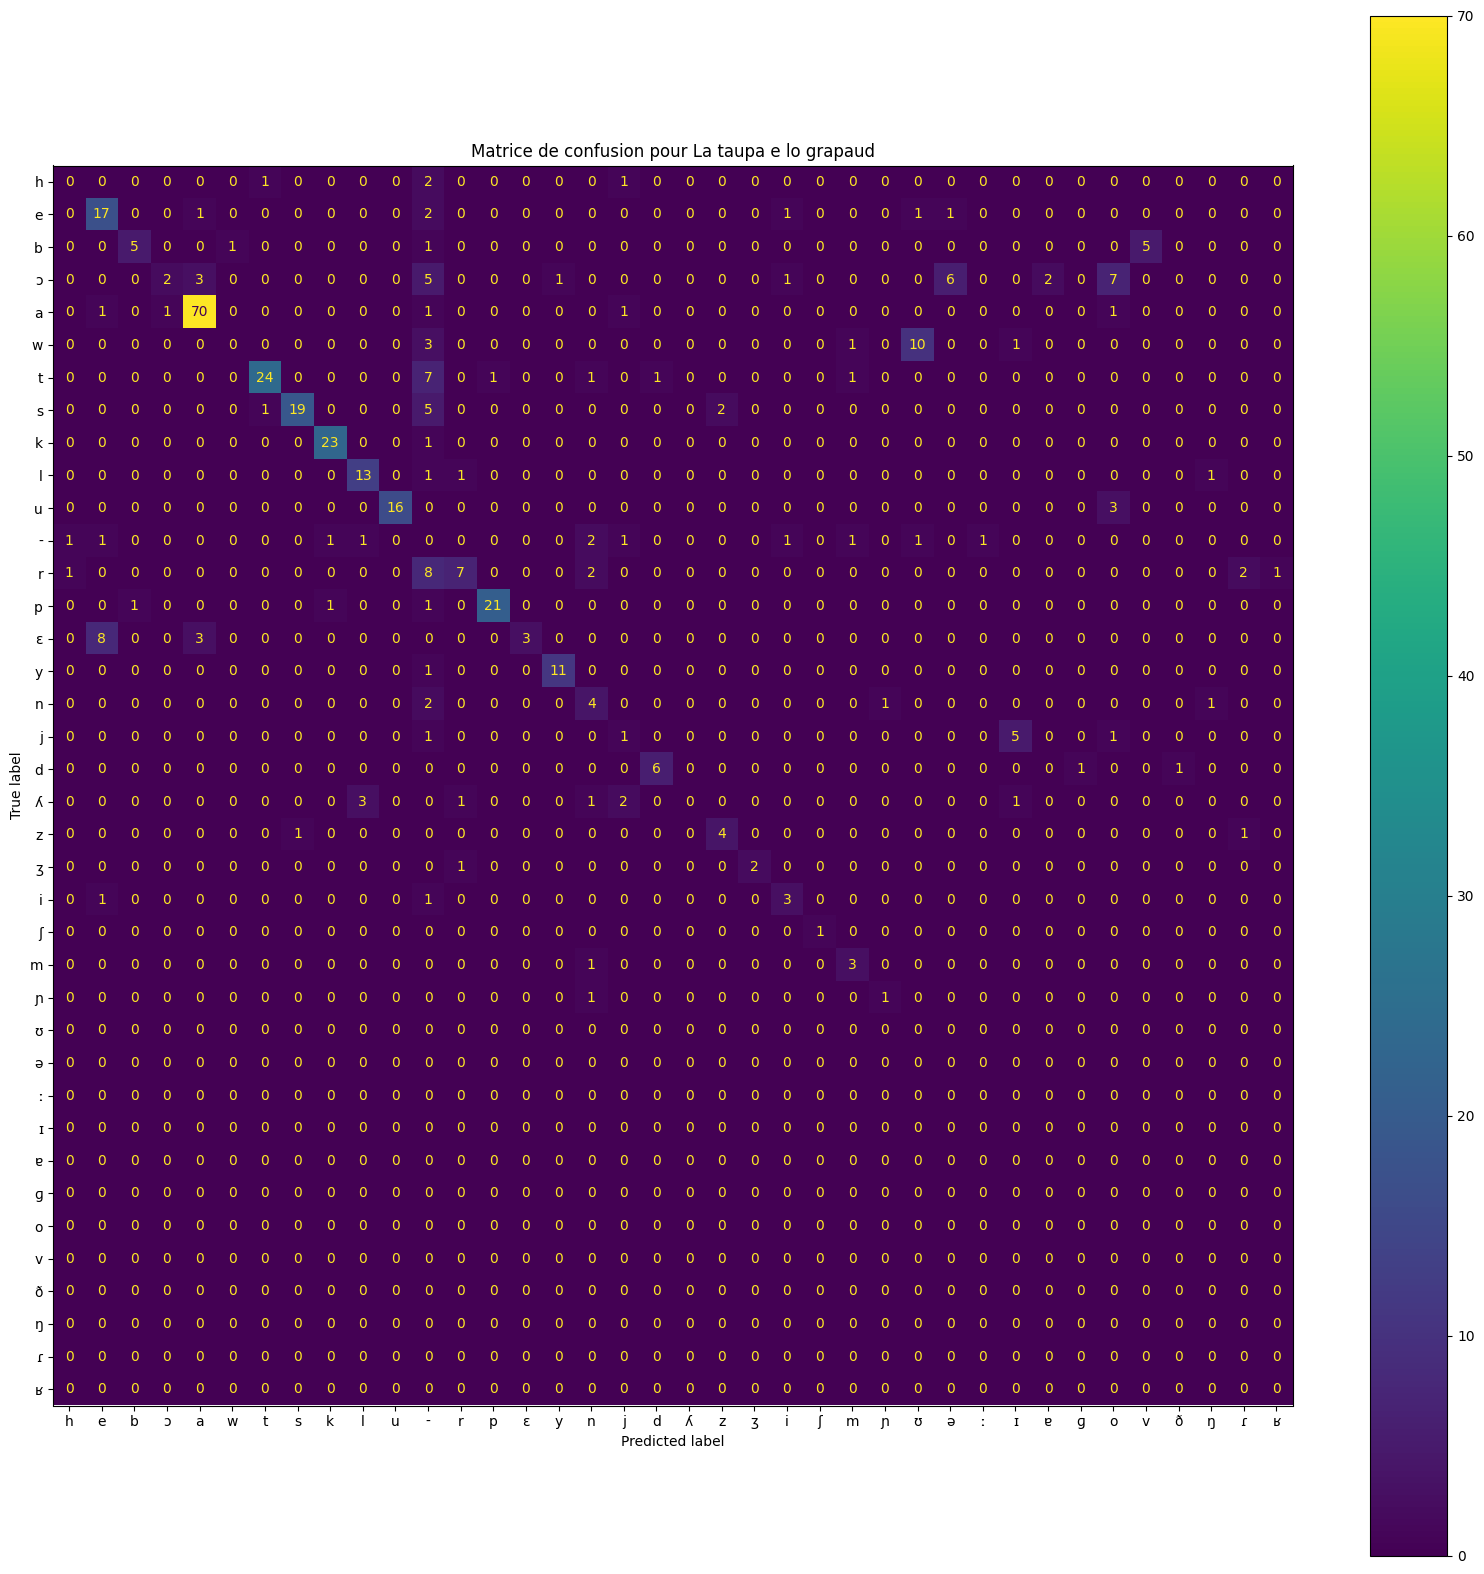

In [15]:
matrice_confusion("La taupa e lo grapaud", y_test_aligned, y_pred_aligned)